<a href="https://colab.research.google.com/github/jesusvilla5333-cmd/TAREA-ACADEMICA-3/blob/main/TA3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Las cuatro librerías se importaron correctamente.")

Las cuatro librerías se importaron correctamente.


In [3]:
from google.colab import drive
drive.mount("/content/drive")
ruta_archivo="/content/drive/MyDrive/analítica de datos /jesús/pedidos_campus_250.csv"

Mounted at /content/drive


In [4]:
data = pd.read_csv(ruta_archivo, encoding="latin1", sep=";")
data.head(250)

,ID Pedido,Fecha y Hora Solicitud,Canal de Ingreso,Tipo de Kit,Cantidad,Monto Total (S/),Método de Pago,Hora Despacho,Tiempo Entrega (min),Punto de Entrega,Estado del Pedido
0,PED-2026-001,2026-10-12 18:07:20,WhatsApp,Campus Basic,1,S/ 5.00,Efectivo,18:14:14,6.9,Cafetería Principal,Entregado
1,PED-2026-002,2026-10-12 15:43:29,WhatsApp,Campus Basic,1,S/ 5.00,Yape,15:48:13,4.7,Torre B - Hall,Entregado
2,PED-2026-003,2026-10-13 17:27:59,WhatsApp,Campus Basic,2,S/ 10.00,Yape,17:31:15,3.3,Cafetería Principal,Entregado
3,PED-2026-004,2026-10-13 12:08:38,WhatsApp,Campus Exam,1,S/ 7.50,Yape,12:15:44,7.1,Patio Central,Entregado
4,PED-2026-005,2026-10-13 14:43:07,WhatsApp,Campus Exam,1,S/ 7.50,Plin,14:47:21,4.2,Patio Central,Entregado
...,...,...,...,...,...,...,...,...,...,...,...
245,PED-2026-246,2026-10-15 09:01:03,WhatsApp,Campus Basic,1,S/ 5.00,Yape,09:09:27,8.4,Cafetería Principal,Entregado
246,PED-2026-247,2026-10-13 10:14:40,Código QR,Campus Exam,1,S/ 7.50,Yape,10:20:40,6.0,Torre A - Piso 1,Entregado
247,PED-2026-248,2026-10-12 16:56:38,Código QR,Campus Exam,1,S/ 7.50,Efectivo,17:00:29,3.9,Torre A - Piso 1,Entregado
248,PED-2026-249,2026-10-12 10:42:00,WhatsApp,Campus Basic,3,S/ 15.00,Efectivo,10:48:54,6.9,Puerta Principal,Entregado


In [5]:
print("Total de filas:", len(data))
print("Columnas:", data.shape[1])

Total de filas: 250
Columnas: 11


In [6]:
import pandas as pd

intervalos = [0, 5, 10, 15, 20, 25]
tabla_frecuencias = pd.cut(
    data["Tiempo Entrega (min)"], bins=intervalos, right=False
).value_counts(sort=False)

display(tabla_frecuencias.to_frame(name="Frecuencia"))
print("Total de datos agrupados:", tabla_frecuencias.sum())

,Frecuencia
Tiempo Entrega (min),
"[0, 5)",103
"[5, 10)",147
"[10, 15)",0
"[15, 20)",0
"[20, 25)",0


Total de datos agrupados: 250


In [7]:
intervalos = [0, 10, 20, 30, 40, 50, 60]

tabla_frecuencias = pd.cut(
    data["Tiempo Entrega (min)"], bins=intervalos, right=False
).value_counts(sort=False)

display(tabla_frecuencias.to_frame(name="Frecuencia"))
print("Total de cuentas agrupadas:", tabla_frecuencias.sum())

,Frecuencia
Tiempo Entrega (min),
"[0, 10)",250
"[10, 20)",0
"[20, 30)",0
"[30, 40)",0
"[40, 50)",0
"[50, 60)",0


Total de cuentas agrupadas: 250


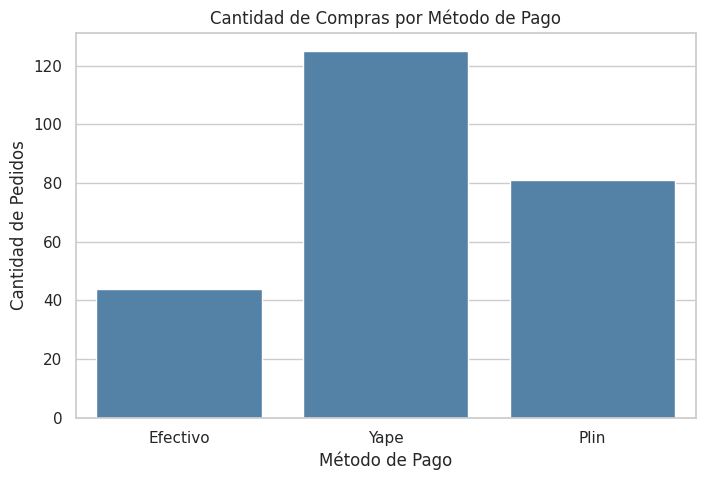

In [11]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.countplot(
    data=data, x="Método de Pago", color="steelblue"
)
plt.title("Cantidad de Compras por Método de Pago")
plt.xlabel("Método de Pago")
plt.ylabel("Cantidad de Pedidos")
plt.show()

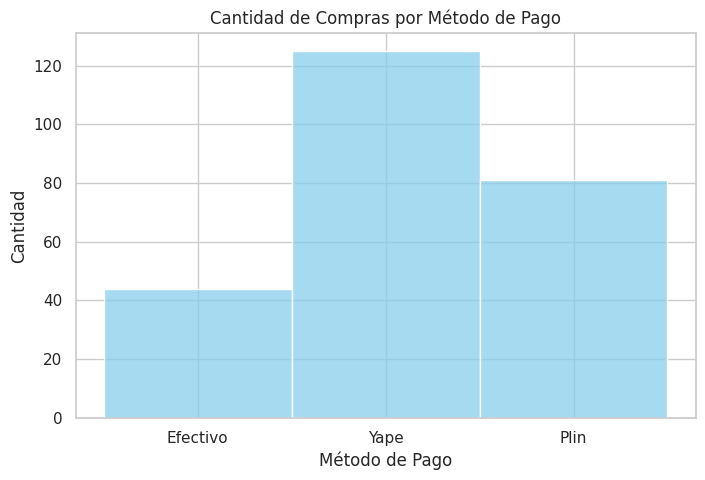

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=data,
    x="Método de Pago",
    discrete=True,
    color="skyblue",
)
plt.title("Cantidad de Compras por Método de Pago")
plt.xlabel("Método de Pago")
plt.ylabel("Cantidad")
plt.show()

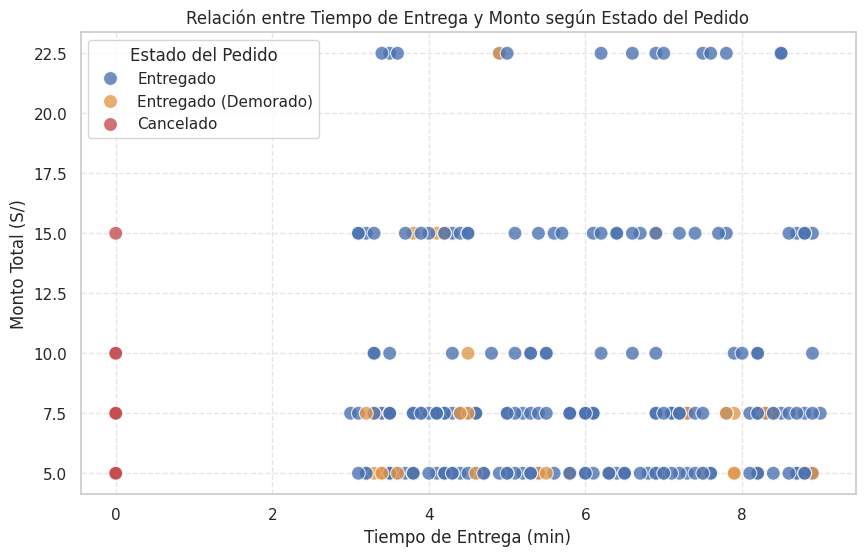

In [34]:
# 1. Aseguramos que la columna de Monto sea numérica
if data["Monto Total (S/)"].dtype == 'object':
    data["Monto Total (S/)"] = data["Monto Total (S/)"].str.replace("S/ ", "", regex=False).str.replace(",", ".").astype(float)

# 2. Creamos el gráfico de dispersión por Estado del Pedido
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data,
    x="Tiempo Entrega (min)",
    y="Monto Total (S/)",
    hue="Estado del Pedido",
    palette={
        "Entregado": "#4C72B0",
        "Entregado (Demorado)": "#E1974C",
        "Cancelado": "#C44E52"
    },
    s=100,
    alpha=0.8
)

plt.title("Relación entre Tiempo de Entrega y Monto según Estado del Pedido")
plt.xlabel("Tiempo de Entrega (min)")
plt.ylabel("Monto Total (S/)")
plt.legend(title="Estado del Pedido")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

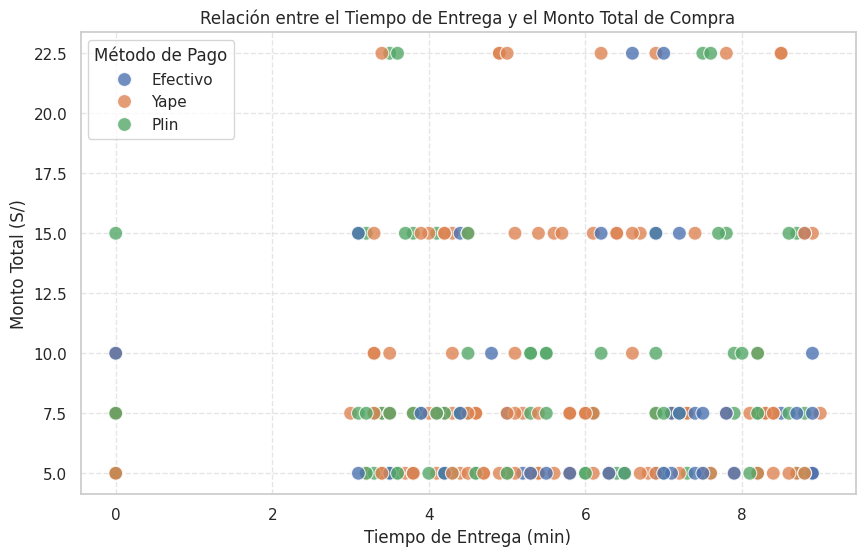

In [32]:
# 1. Limpiamos la columna de Monto para convertirla a número float si aún no lo está
if data["Monto Total (S/)"].dtype == 'object':
    data["Monto Total (S/)"] = data["Monto Total (S/)"].str.replace("S/ ", "", regex=False).str.replace(",", ".").astype(float)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data,
    x="Tiempo Entrega (min)",
    y="Monto Total (S/)",
    hue="Método de Pago",
    palette={"Efectivo": "#4C72B0", "Yape": "#DD8452", "Plin": "#55A868"},
    s=100,
    alpha=0.8
)

plt.title("Relación entre el Tiempo de Entrega y el Monto Total de Compra")
plt.xlabel("Tiempo de Entrega (min)")
plt.ylabel("Monto Total (S/)")
plt.legend(title="Método de Pago")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

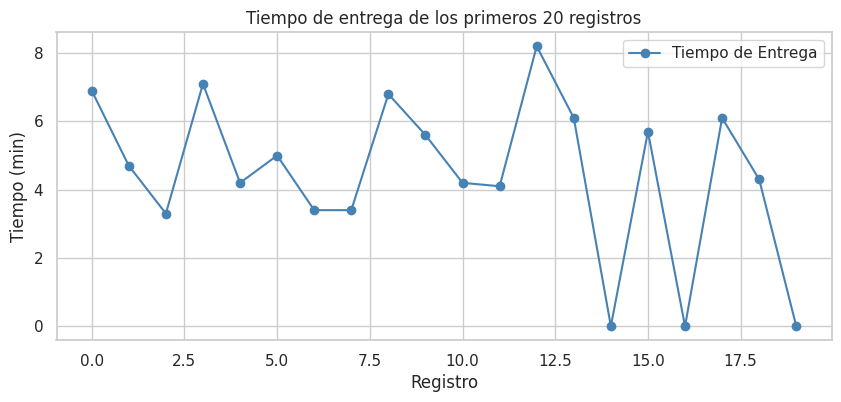

In [35]:
import matplotlib.pyplot as plt

# Asegúrate de ejecutar primero la celda de la lectura del CSV (data = pd.read_csv...)
plt.figure(figsize=(10, 4))
plt.plot(
    data["Tiempo Entrega (min)"].head(20),
    marker="o",
    color="steelblue",
    label="Tiempo de Entrega"
)
plt.title("Tiempo de entrega de los primeros 20 registros")
plt.xlabel("Registro")
plt.ylabel("Tiempo (min)")
plt.legend()
plt.grid(True)
plt.show()